In [1]:
print("Hello, World!")

Hello, World!


In [2]:
import numpy as np

In [3]:
def count_and_verify_eigenvalues(A: np.ndarray) -> tuple[np.ndarray, np.ndarray, bool]:
    eigenvalues, eigenvectors = np.linalg.eig(A)

    eigenvalues, eigenvectors = np.real(eigenvalues), np.real(eigenvectors)

    all_correct = True
    for i in range(len(eigenvalues)):
        lam = eigenvalues[i]
        v = eigenvectors[:, i]

        lhs = A @ v
        rhs = lam * v

        if not np.allclose(lhs, rhs):
            all_correct = False

        print(f"Eigenvalue λ_{i+1} = {lam:.4f}")
        print(f"  Eigenvector v_{i+1} = {v.round(4)}")
        print(f"  A @ v              = {lhs.round(4)}")
        print(f"  λ * v              = {rhs.round(4)}")
        print(f"  Verification       = {'SUCCESS' if all_correct else 'FAILED'}\n")

    return eigenvalues, eigenvectors, all_correct

A = np.array([
    [4, 1],
    [2, 3]
])    

print(f"Matrix: {A}")

eigval, eigvec, status = count_and_verify_eigenvalues(A)
print(f"status: {status}")

Matrix: [[4 1]
 [2 3]]
Eigenvalue λ_1 = 5.0000
  Eigenvector v_1 = [0.7071 0.7071]
  A @ v              = [3.5355 3.5355]
  λ * v              = [3.5355 3.5355]
  Verification       = SUCCESS

Eigenvalue λ_2 = 2.0000
  Eigenvector v_2 = [-0.4472  0.8944]
  A @ v              = [-0.8944  1.7889]
  λ * v              = [-0.8944  1.7889]
  Verification       = SUCCESS

status: True


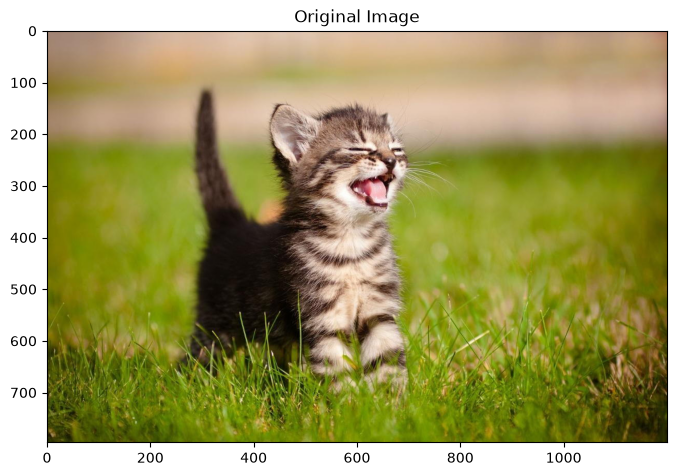

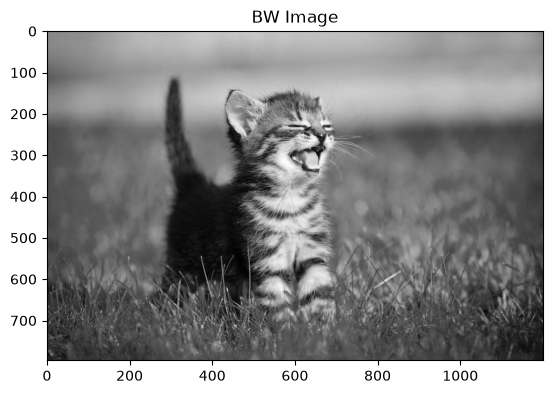

In [4]:
from matplotlib.image import imread
import matplotlib.pyplot as plt

image_raw = imread("img/img.jpg")

plt.figure(figsize=(8, 6))
plt.imshow(image_raw)
plt.title("Original Image")
plt.axis('on')
plt.show()

# with open('img.txt', 'w') as f:
#     np.set_printoptions(threshold=np.inf)
#     f.write(str(image_raw))
#     np.set_printoptions(threshold=1000)

image_sum = image_raw.sum(axis=2)
image_bw = image_sum / image_sum.max()
plt.imshow(image_bw, cmap='grey')
plt.title("BW Image")
plt.axis('on')
plt.show()

    

Number of components explaining 95% variance: 28


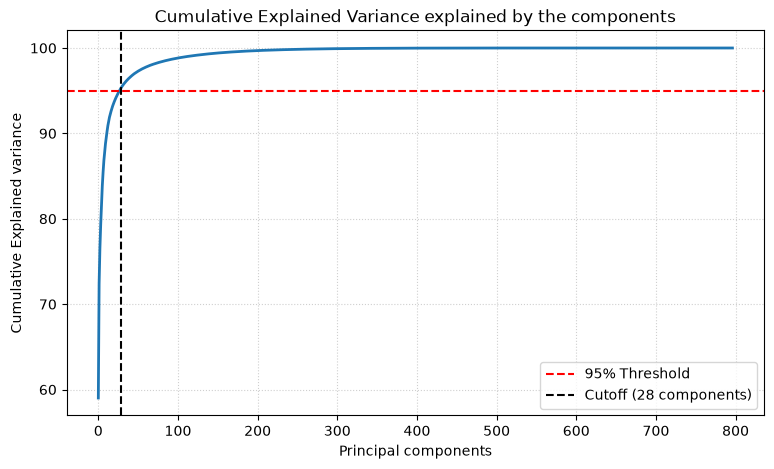

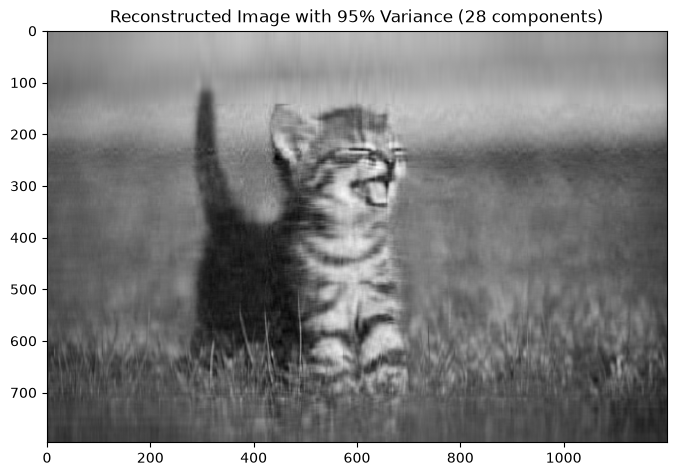

In [ ]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(image_bw)

cumsum_variance = np.cumsum(pca.explained_variance_ratio_) * 100

n_components_95 = np.argmax(cumsum_variance >= 95) + 1
print(f"Number of components explaining 95% variance: {n_components_95}")

# graph illustration
plt.figure(figsize=(9, 5))
plt.plot(cumsum_variance, color='tab:blue', linewidth=2)
plt.axhline(y=95, color='r', linestyle='--', label='95% Threshold')
plt.axvline(x=n_components_95, color='k', linestyle='--', label=f'Cutoff ({n_components_95} components)')

plt.title('Cumulative Explained Variance explained by the components', fontsize=12)
plt.xlabel('Principal components', fontsize=10)
plt.ylabel('Cumulative Explained variance', fontsize=10)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


pca_95 = PCA(n_components=n_components_95)
image_reconstructed_95 = pca_95.inverse_transform(pca_95.fit_transform(image_bw))

plt.figure(figsize=(8, 6))
plt.imshow(image_reconstructed_95, cmap='gray')
plt.title(f"Reconstructed Image with 95% Variance ({n_components_95} components)")
plt.axis('on')
plt.show()

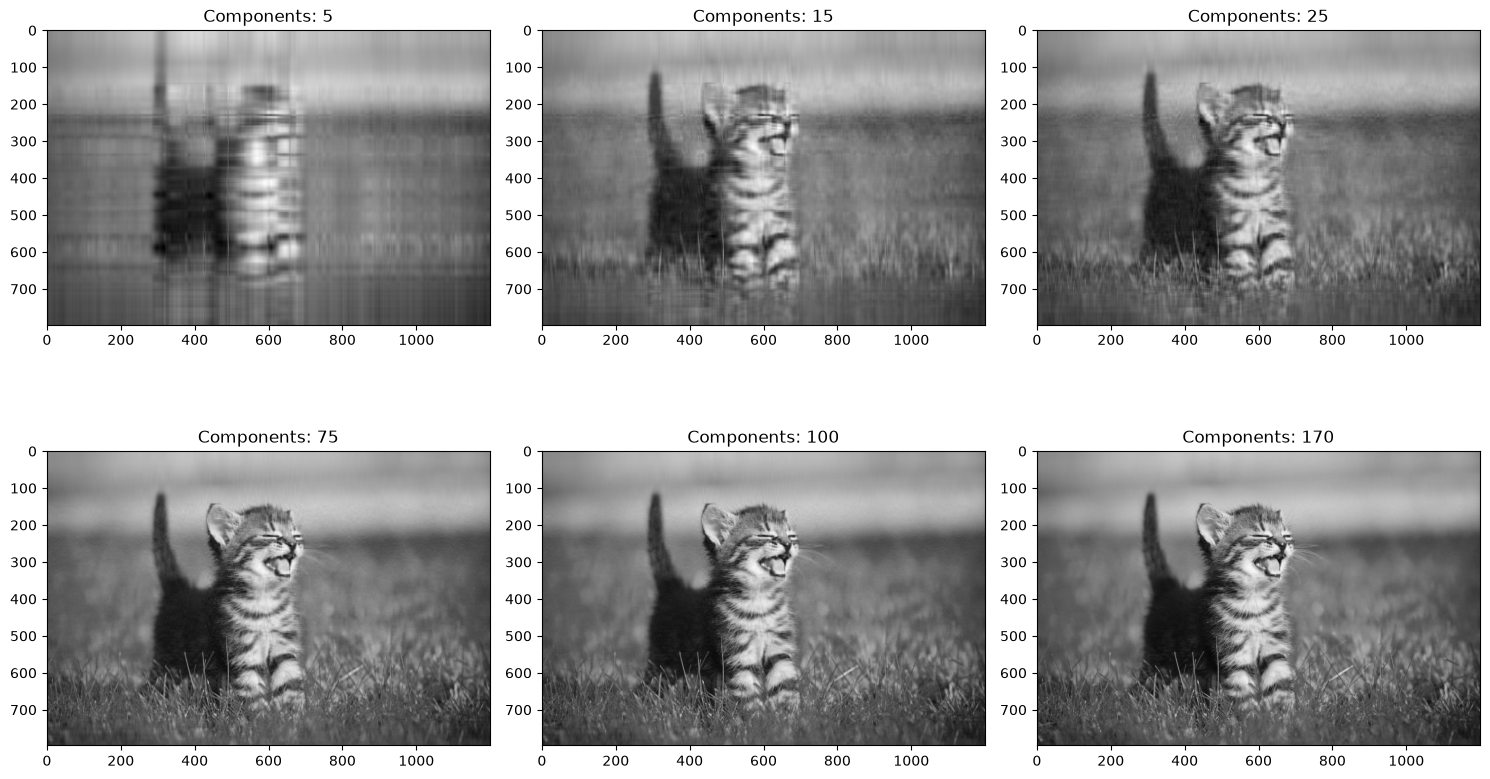

In [6]:
components_list = [5, 15, 25, 75, 100, 170]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for idx, n_comp in enumerate(components_list):
    pca_temp = PCA(n_components=n_comp)
    img_reconstructed = pca_temp.inverse_transform(pca_temp.fit_transform(image_bw))

    axes[idx].imshow(img_reconstructed, cmap='gray')
    axes[idx].set_title(f"Components: {n_comp}")
    axes[idx].axis('on')

plt.tight_layout()
plt.show()

**Did you get a sharper image?**

Yes, the image becomes sharper when there are more components

**What if you take fewer components?**

Small details and outlines become less recognizable, the image becomes blurry, but main big objects still can be distinguished.